In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from PIL import Image
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import torch.nn.utils as utils
import torchvision.utils as vutils
import numpy as np
from torch.utils.data import DataLoader, Dataset
import cv2
import os

**Data**

In [2]:
image_dir = 'dataset/train/'

In [3]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, .5, .5]),
])


class Flower102(Dataset):
    def __init__(self, transform=None):
        image_paths = [list(map(lambda name: class_name + '/' + name, os.listdir(image_dir + class_name))) for class_name in os.listdir(image_dir)]
        image_paths = sum(image_paths, [])
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = os.path.join(image_dir, self.image_paths[idx])
        img = Image.open(img_path).convert('RGB')
        return self.transform(img)

dataset = Flower102(transform=transform)

data_loader = DataLoader(dataset, batch_size=128, shuffle=True, pin_memory=True)

p**Models saving / loading**

In [4]:
def save_checkpoint(model, path):
    state_dict = model.state_dict()
    torch.save(state_dict, path)


def save_models(netG, nameG, netD, nameD):
    save_checkpoint(netG, path=f'models/generator/{nameG}')
    save_checkpoint(netD, path=f'models/discriminator/{nameD}')


def load_checkpoint(model, path):
    state_dict = torch.load(path)
    model.load_state_dict(state_dict)

def load_models(netG, nameG, netD, nameD):
    load_checkpoint(netG, path=f'models/generator/{nameG}')
    load_checkpoint(netD, path=f'models/discriminator/{nameD}')

**Architechture**

In [5]:
class Discriminator(nn.Module):
    def __init__(self, nc=3, ndf=64):
        super(Discriminator, self).__init__()

        self.skip1 = nn.Sequential(
            nn.AvgPool2d(4),
            nn.utils.spectral_norm(nn.Conv2d(nc, ndf * 2, kernel_size=1, bias=False)),
        )

        self.main1 = nn.Sequential(
            utils.spectral_norm(nn.Conv2d(nc, ndf, kernel_size=4, stride=2, padding=1, bias=False)),
            nn.LeakyReLU(0.2, inplace=True),

            utils.spectral_norm(nn.Conv2d(ndf, ndf, kernel_size=3, padding=1, bias=False)),
            # ЗДЕСЬ УБРАН LeakyReLU, который мешал (раньше его не было)

            utils.spectral_norm(nn.Conv2d(ndf, ndf * 2, kernel_size=4, stride=2, padding=1, bias=False)),
            nn.LeakyReLU(0.2, inplace=True),
        )

        self.skip2 = nn.Sequential(
            nn.AvgPool2d(4),
            nn.utils.spectral_norm(nn.Conv2d(ndf * 2, ndf * 8, kernel_size=1, bias=False)),
        )

        self.main2 = nn.Sequential(
            utils.spectral_norm(nn.Conv2d(ndf * 2, ndf * 4, kernel_size=4, stride=2, padding=1, bias=False)),
            nn.LeakyReLU(0.2, inplace=True),

            # ЗДЕСЬ ПОЛНОСТЬЮ УБРАН БЛОК 3x3 (Conv + LeakyReLU),
            # так как чекпоинт "не знает" о нем и пытается загрузить следующие веса сюда.

            utils.spectral_norm(nn.Conv2d(ndf * 4, ndf * 8, kernel_size=4, stride=2, padding=1, bias=False)),
            nn.LeakyReLU(0.2, inplace=True),
        )

        self.skip3 = nn.Sequential(
            nn.AvgPool2d(4),
            nn.utils.spectral_norm(nn.Conv2d(ndf * 8, 1, kernel_size=1, bias=False)),
        )

        self.main3 = nn.Sequential(
            utils.spectral_norm(nn.Conv2d(ndf * 8, ndf * 16, kernel_size=4, stride=2, padding=1, bias=False)),
            nn.LeakyReLU(0.2, inplace=True),

            utils.spectral_norm(nn.Conv2d(ndf * 16, 1, kernel_size=4, stride=2, padding=1, bias=False)),
        )

    def forward(self, x):
        x = self.skip1(x) + self.main1(x)
        x = self.skip2(x) + self.main2(x)
        x = self.skip3(x) + self.main3(x)
        return x.view(-1, 1).squeeze(1)

In [6]:
# --- 1. Инициализация весов ---
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        if hasattr(m, 'weight') and m.weight is not None:
            nn.init.normal_(m.weight.data, 0.0, 0.02)
        if hasattr(m, 'bias') and m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif classname.find('Linear') != -1:
        if hasattr(m, 'weight') and m.weight is not None:
            nn.init.normal_(m.weight.data, 0.0, 0.02)
        if hasattr(m, 'bias') and m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)
    elif classname.find('BatchNorm') != -1 or classname.find('InstanceNorm') != -1:
        if hasattr(m, 'weight') and m.weight is not None:
            nn.init.normal_(m.weight.data, 1.0, 0.02)
        if hasattr(m, 'bias') and m.bias is not None:
            nn.init.constant_(m.bias.data, 0.0)


In [7]:
import torch.nn.functional as F


# 1. Сначала определяем сам слой SwiGLU
class SwiGLU(nn.Module):
    def forward(self, x):
        # x: (B, 2*C, H, W)
        x, gate = x.chunk(2, dim=1) # Разрезаем каналы пополам
        return x * F.silu(gate)     # Умножаем контент на "ворота" (SiLU = Swish)


class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-8):
        super().__init__()
        self.eps = eps
        # Обучаемый параметр (Gamma), инициализирован единицами
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        # x: (Batch, Channels, Height, Width)
        rrms = torch.rsqrt(x.pow(2).mean(dim=1, keepdim=True) + self.eps)
        x_norm = x * rrms
        return x_norm * self.weight.view(1, -1, 1, 1)


# 2. Обновленный StyleBlock
class StyleBlock(nn.Module):
    def __init__(self, in_channels, out_channels, w_dim):
        super().__init__()

        # --- SKIP CONNECTION ---
        # Оставляем как было, он переводит in -> out
        self.skip = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        )

        # --- MAIN PATH (Здесь магия) ---
        # ВАЖНО: Мы умножаем выходные каналы на 2,
        # потому что SwiGLU потом схлопнет их обратно в out_channels
        hidden_channels = out_channels * 2

        self.conv = nn.Conv2d(in_channels, hidden_channels, 3, 1, 1, bias=False)
        self.norm = RMSNorm(hidden_channels)

        # Вместо LeakyReLU ставим SwiGLU (он не требует параметров в __init__, это просто функция)
        self.act = SwiGLU()

        # --- STYLE INJECTION (AdaIN) ---
        # Теперь мы должны генерировать стили для удвоенного кол-ва каналов
        self.style_scale = nn.Linear(w_dim, hidden_channels)
        self.style_bias = nn.Linear(w_dim, hidden_channels)

        # --- NOISE INJECTION ---
        # Шум тоже должен проецироваться в удвоенные каналы
        self.noise_proj = nn.Sequential(
            nn.Conv2d(1, hidden_channels, kernel_size=3, padding=1, bias=False), # in=1 (fix)
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(hidden_channels, hidden_channels, kernel_size=1, bias=False)
        )

        # Инициализация
        self.style_scale.weight.data.fill_(0)
        self.style_scale.bias.data.fill_(1.0)
        self.style_bias.weight.data.fill_(0)
        self.style_bias.bias.data.fill_(0.0)

        self.skip_scale = nn.Parameter(torch.ones(1) / 10)


    def forward(self, x, w):
        x_skip = self.skip(x)

        # 1. Conv
        x = self.conv(x)      # (B, 2*Out, H, W)
        x = self.norm(x)

        # 2. AdaIN (на 2*Out каналов)
        style_s = self.style_scale(w).view(x.size(0), -1, 1, 1)
        style_b = self.style_bias(w).view(x.size(0), -1, 1, 1)
        x = x * style_s + style_b

        # 3. Noise (на 2*Out каналов)
        noise = torch.randn(x.size(0), 1, x.size(2), x.size(3), device=x.device)
        noise = self.noise_proj(noise)
        x = x + noise

        # 4. SwiGLU Activation
        # Здесь (B, 2*Out, H, W) превращается в (B, Out, H, W)
        x = self.act(x)

        # 5. Sum with Skip
        return x + x_skip * self.skip_scale

In [8]:
class SelfAttention(nn.Module):
    def __init__(self, in_dim):
        super(SelfAttention, self).__init__()
        self.query_conv = nn.Conv2d(in_dim, in_dim // 8, kernel_size=1)
        self.key_conv = nn.Conv2d(in_dim, in_dim // 8, kernel_size=1)
        self.value_conv = nn.Conv2d(in_dim, in_dim, kernel_size=1)
        self.gamma = nn.Parameter(torch.zeros(1))
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        """
        inputs : x input feature maps( B X C X W X H)
        returns : out attention value + input feature
                  attention: B X (HxW) X (HxW)
        """
        m_batchsize, C, width, height = x.size()

        # Query, Key, Value
        proj_query = self.query_conv(x).view(m_batchsize, -1, width * height).permute(0, 2, 1)
        proj_key = self.key_conv(x).view(m_batchsize, -1, width * height)
        energy = torch.bmm(proj_query, proj_key)
        attention = self.softmax(energy)

        proj_value = self.value_conv(x).view(m_batchsize, -1, width * height)

        out = torch.bmm(proj_value, attention.permute(0, 2, 1))
        out = out.view(m_batchsize, C, width, height)

        # Skip-connection внутри Attention:
        # Сначала gamma=0, поэтому слой ничего не делает (Identity).
        # Сеть сама решит, когда начать использовать внимание.
        out = self.gamma * out + x
        return out

In [9]:
class LearnableBlur(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, padding=1, groups=channels, bias=False)

        filter_kernel = torch.tensor([[1, 2, 1],
                                      [2, 4, 2],
                                      [1, 2, 1]], dtype=torch.float32)
        filter_kernel = filter_kernel / filter_kernel.sum()
        with torch.no_grad():
            self.conv.weight.data.copy_(filter_kernel.view(1, 1, 3, 3).repeat(channels, 1, 1, 1))

    def forward(self, x):
        return self.conv(x)


class PixelShuffleBlock(nn.Module):
    def __init__(self, in_channels, out_channels, scale_factor=2):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels * (scale_factor ** 2), kernel_size=3, padding=1)
        self.ps = nn.PixelShuffle(scale_factor)
        self.blur = LearnableBlur(out_channels)

        self.act = nn.LeakyReLU(0.2, inplace=True)
        self._icnr_init(self.conv.weight, scale_factor)

    def forward(self, x):
        x = self.conv(x)
        x = self.ps(x)
        x = self.blur(x) # Сеть сама решит, размывать ли ей сетку
        return self.act(x)

    def _icnr_init(self, tensor, scale_factor):
        # Эта инициализация заставляет PixelShuffle в начале обучения
        # вести себя как "хороший" апсемплинг, а не рандомный шум.
        with torch.no_grad():
            if isinstance(tensor, nn.Parameter):
                tensor = tensor.data
            out_c, in_c, k_h, k_w = tensor.size()

            # 1. Генерируем веса как для обычной свертки (уменьшенной)
            kernel = torch.randn(out_c // (scale_factor ** 2), in_c, k_h, k_w)
            nn.init.kaiming_normal_(kernel)

            # 2. Растягиваем эти веса (Upsample)
            # Это делает так, что соседние пиксели инициализируются коррелированными значениями
            kernel = kernel.repeat(scale_factor ** 2, 1, 1, 1)
            tensor.copy_(kernel)

    def forward(self, x):
        return self.act(self.ps(self.conv(x)))

In [10]:
class Generator(nn.Module):
    def __init__(self, nz=100, ngf=64, nc=3):
        super().__init__()
        # ... (код Mapping Network и input_const тот же) ...
        self.mapping = nn.Sequential(nn.Linear(nz, 128), nn.LeakyReLU(0.2), nn.Linear(128, 128))
        self.input_const = nn.Parameter(torch.randn(1, ngf*16, 4, 4))
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)

        # Блоки
        self.block0 = StyleBlock(ngf*16, ngf*8, 128)
        self.block1 = StyleBlock(ngf*8, ngf*4, 128) # -> 8x8
        self.block2 = StyleBlock(ngf*4, ngf*2, 128) # -> 16x16
        self.block3 = StyleBlock(ngf*2, ngf, 128)   # -> 32x32

        # --- ВСТАВЛЯЕМ ATTENTION СЮДА (на 32x32) ---
        self.attention = SelfAttention(ngf)

        # Выход
        self.to_rgb = nn.Sequential(
            PixelShuffleBlock(ngf, ngf, scale_factor=2),
            nn.Conv2d(ngf, nc, 3, 1, 1),
            nn.Tanh()
        )

    def forward(self, z):
        z = z.view(z.size(0), -1) # Страховка от 300x1
        w = self.mapping(z)
        x = self.input_const.repeat(z.size(0), 1, 1, 1)

        x = self.block0(x, w)
        x = self.upsample(x); x = self.block1(x, w)
        x = self.upsample(x); x = self.block2(x, w)
        x = self.upsample(x); x = self.block3(x, w)

        # --- ПРИМЕНЯЕМ ВНИМАНИЕ ---
        x = self.attention(x)

        return self.to_rgb(x)

In [11]:
import copy
import torch


class EMA:
    def __init__(self, model, decay=0.999):
        self.decay = decay
        # Создаем полную копию модели, которая не будет требовать градиентов
        self.shadow = copy.deepcopy(model)
        # Отключаем расчет градиентов для копии, чтобы экономить память
        for param in self.shadow.parameters():
            param.requires_grad = False

        # Переносим на то же устройство (GPU/CPU), что и оригинал
        self.shadow.to(next(model.parameters()).device)

    def update(self, model):
        """Обновляет веса EMA модели на основе текущей тренируемой модели"""
        with torch.no_grad():
            # Проходим по всем параметрам (весам) обеих моделей
            for name, param in model.named_parameters():
                if param.requires_grad:
                    # Формула: new_average = old_average * decay + current * (1 - decay)
                    # Используем .data для прямого доступа к тензорам
                    shadow_param = dict(self.shadow.named_parameters())[name]
                    shadow_param.data.mul_(self.decay).add_(param.data, alpha=(1.0 - self.decay))

            # Также копируем буферы (например, статистику BatchNorm: running_mean, running_var)
            # Их усреднять нельзя, их просто копируем
            for name, buffer in model.named_buffers():
                shadow_buffer = dict(self.shadow.named_buffers())[name]
                shadow_buffer.data.copy_(buffer.data)


    def get_model(self):
        """Возвращает EMA модель для инференса/сохранения"""
        return self.shadow

**Models definition**

In [12]:
# Параметры
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LR = 2e-4
BETA1 = 0.0
BETA2 = 0.9

netG = Generator(nz=100, ngf=64, nc=3).to(device)
netD = Discriminator(nc=3, ndf=64).to(device)

g_ema = EMA(netG, decay=0.995)

netG.apply(weights_init)
netD.apply(weights_init)

# Сброс инициализации для Mapping Network на Kaiming (стандарт для ReLU сетей)
for m in netG.mapping.modules():
    if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, nonlinearity='leaky_relu')
        nn.init.zeros_(m.bias)

**Training Config**

In [13]:
from torch.optim.lr_scheduler import LambdaLR
from DiffAugment import DiffAugment

# --- Оптимизаторы ---
optimizerG = optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, BETA2))
optimizerD = optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, BETA2))


def lambda_rule(epoch_id):        # Всего эпох
    decay_start_epoch = 250   # С какой эпохи начинать снижать

    if epoch_id < decay_start_epoch:
        return 1.0 # LR не меняется
    else:
        # Линейно от 1.0 до 0.0
        decay_len = n_epochs - decay_start_epoch
        return 1.0 - (epoch_id - decay_start_epoch) / float(decay_len)


scheduler_G = LambdaLR(optimizerG, lr_lambda=lambda_rule)
scheduler_D = LambdaLR(optimizerD, lr_lambda=lambda_rule)

policy = ''

def get_aug_prob(epoch_id):
    return min(1.0, epoch_id / 100)

**Image Generation / Presentation**

In [17]:
def generate_images(netG, n_images=4):
    with torch.no_grad():
        noise = torch.randn(n_images, 100, device=device, requires_grad=False) / 100
        images = netG(noise).detach().cpu()
    return images

In [15]:
def show_images(netG, title, n_images=4):
    images = generate_images(netG, n_images)
    # make_grid сам соберет картинки в одну строку (nrow=len(images))
    # normalize=True сам переведет из диапазона сети в [0, 1]
    grid = vutils.make_grid(images.detach().cpu(), nrow=len(images), padding=2, normalize=True)

    plt.figure(figsize=(len(images) * 2, 3))
    plt.axis("off")
    plt.title(f"epoch №{title}")

    # make_grid возвращает (C, H, W), поэтому всё равно нужно permute для imshow
    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.show()

**Training Loop**

Epoch 	[0/500], Discriminator Loss: 1061.125


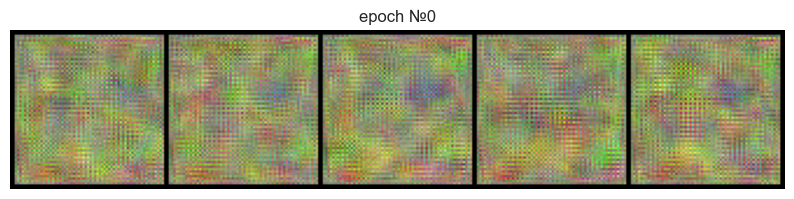

KeyboardInterrupt: 

In [16]:
n_epochs = 500

discriminator_losses = []

for epoch in range(n_epochs):
    train_loss_D = 0
    for batch_id, data in enumerate(data_loader):
        # --- ШАГ 1: Обучение Дискриминатора (Критика) ---
        netD.zero_grad()

        # А. Обучение на реальных картинках
        real_imgs = data.to(device, non_blocking=True)
        output_real = netD(DiffAugment(real_imgs, prob=get_aug_prob(epoch), policy=policy))
        # WGAN Loss: мы хотим максимизировать output_real (или минимизировать -output_real)
        loss_d_real = -torch.mean(output_real)

        # Б. Обучение на фейковых картинках
        noise = torch.randn(real_imgs.size(0), 100, device=device)
        fake_imgs = netG(noise)
        output_fake = netD(DiffAugment(fake_imgs.detach(), prob=get_aug_prob(epoch), policy=policy))

        # WGAN Loss: мы хотим минимизировать output_fake (или максимизировать +output_fake)
        loss_d_fake = torch.mean(output_fake)

        # Итоговый лосс дискриминатора
        loss_D = loss_d_real + loss_d_fake
        loss_D.backward()
        optimizerD.step()

        train_loss_D += loss_D.item()

        # --- ШАГ 2: Обучение Генератора ---
        if batch_id % 4 == 0:
            netG.zero_grad()
            output_fake = netD(DiffAugment(fake_imgs, prob=get_aug_prob(epoch), policy=policy))
            # Loss генератора: просто минус среднее скора дискриминатора
            loss_G = -torch.mean(output_fake)

            loss_G.backward()
            optimizerG.step()

            g_ema.update(netG)

    if epoch % 100 == 95:
        save_models(netG, epoch, netD, epoch)
        save_models(g_ema.get_model(), f'gEMA_{epoch}', netD, epoch)

    train_loss_D = train_loss_D / len(data_loader)
    discriminator_losses.append(train_loss_D)

    # Callback
    print(f"Epoch \t[{epoch}/{n_epochs}], Discriminator Loss: {abs(train_loss_D):.3f}")
    show_images(g_ema.get_model(), title=epoch, n_images=5)


 **Вывод сгенерированных картинок**

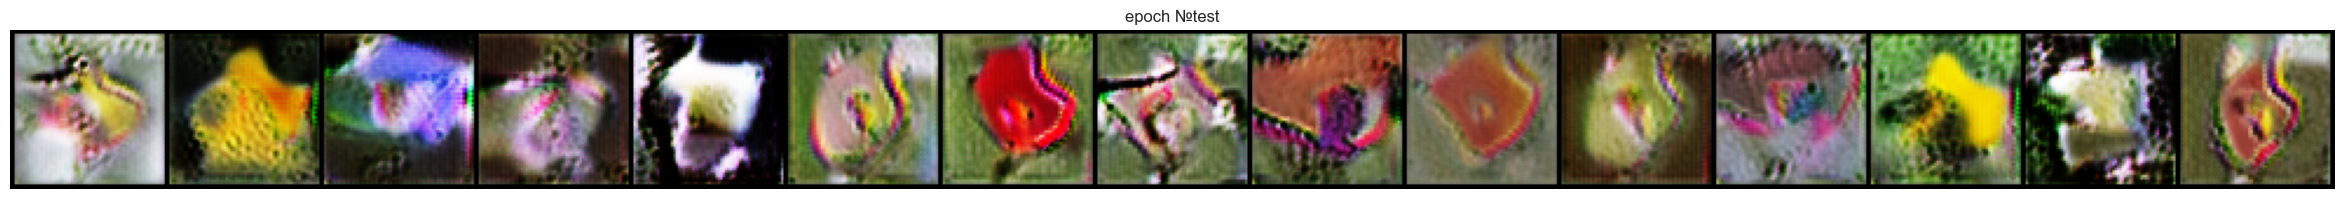

In [54]:
show_images(netG, title='test', n_images=15)

<Axes: >

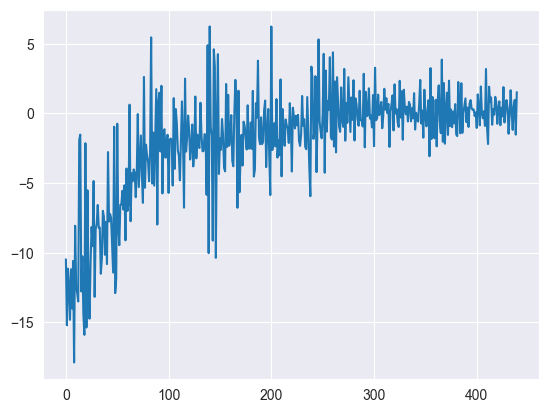

In [64]:
import seaborn as sns

sns.lineplot(discriminator_losses[60:])

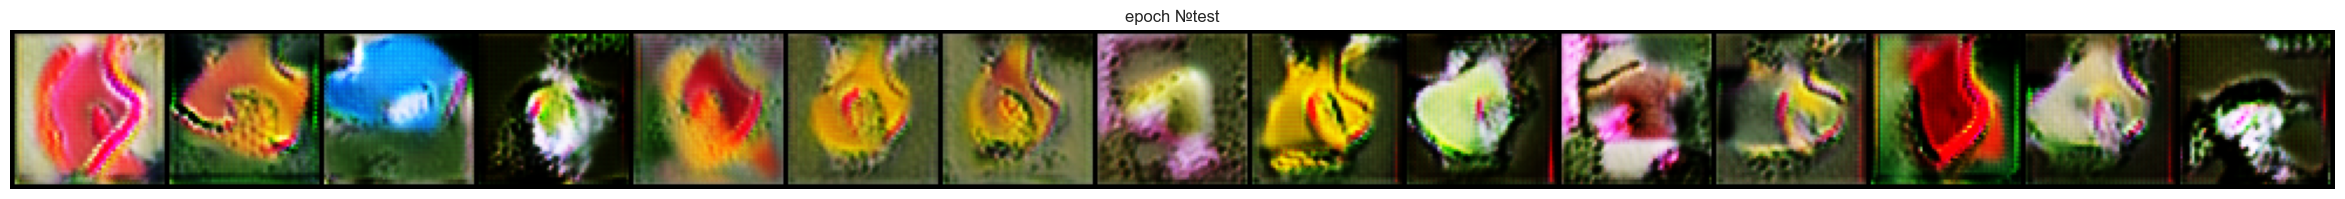

In [28]:
show_images(g_ema.get_model(), title='test', n_images=15)

In [57]:
save_models(netG=netG, nameG=2, netD=netD, nameD=2)
assert False

In [13]:
load_models(netG=netG, nameG=497, netD=netD, nameD=497)
load_models(netG=g_ema.get_model(), nameG='gEMA_497', netD=netD, nameD=497)

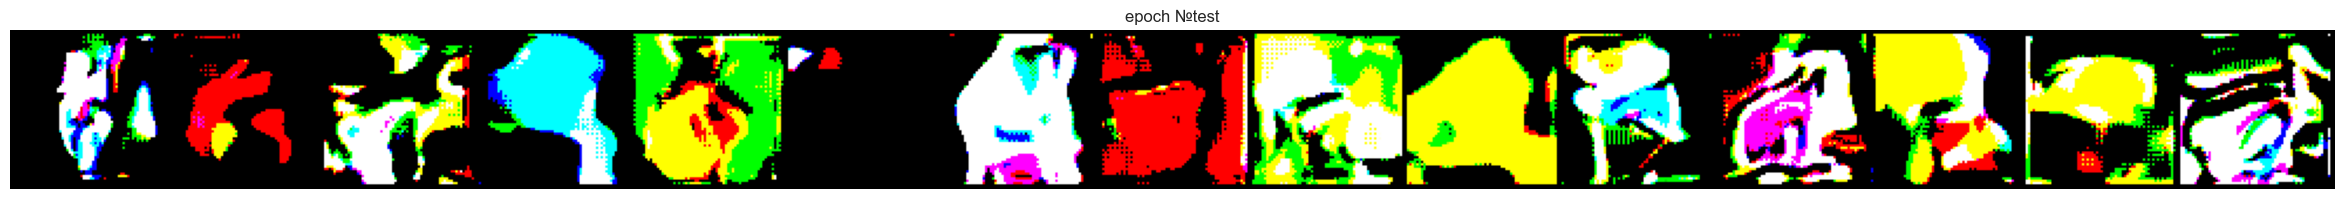

In [16]:
show_images(g_ema.get_model(), title='test', n_images=15)

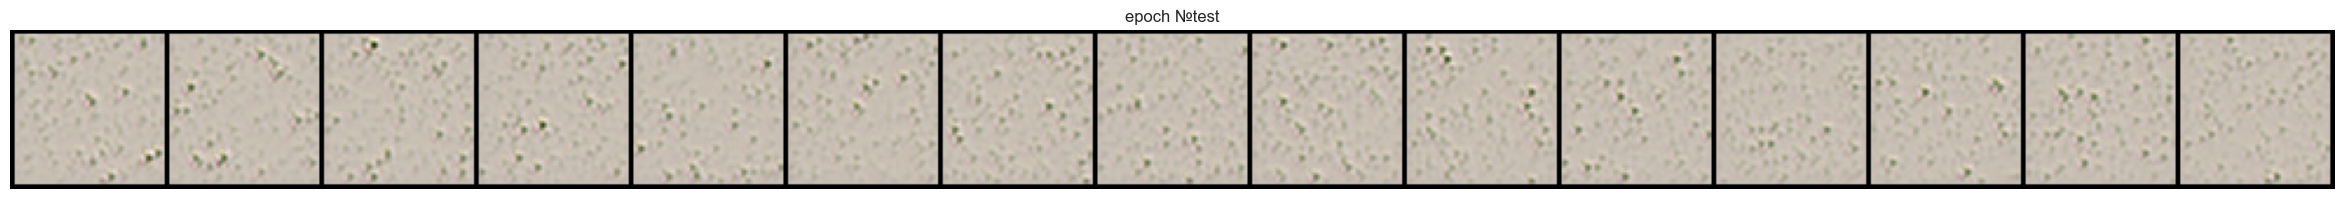

In [18]:
show_images(g_ema.get_model(), title='test', n_images=15)